# Reproducing the thesis results

*Realization and characterization of multilayer neural networks based on a reconfigurable all-optical activation function*, Strahinja Nikolić, ETF Belgrade, 2024.

This notebook regenerates every result figure and table of Chapter 3. All logic lives in the `onn/` package; the notebook only calls it.

`run(name)` loads `results/<name>.json` when it exists and trains otherwise. To retrain everything from scratch, delete `results/` or run `python -m onn.experiments all --force --jobs 5` (about 15 minutes on a laptop CPU). Every number is a mean over 3 seeds.

In [1]:
%matplotlib inline
from IPython.display import Markdown, display
import numpy as np
from onn.experiments import run, EXPERIMENTS
from onn import plotting, report

FORCE = False  # set to True to retrain instead of loading the cached results
R = {name: run(name, force=FORCE) for name in EXPERIMENTS}

## 1. The all-optical activation functions (Sec. 2)

An injection-locked Fabry–Perot laser diode (FP-LD) in its bistable regime acts as a nonlinear unit, with output power as a function of input power. Its shape is reconfigured through the frequency detuning of the injected light.

* **Fig. 2.1**: 12 *measured* transfer curves (3 longitudinal modes × 4 detunings)
* **Fig. 2.2**: a *simulated* 2D lookup table, with 26 detunings from −15 Ω to −40 Ω (Ω = 10¹⁰ rad/s)
* **Fig. 2.3**: simulated power **and phase** curves, used for complex-valued networks

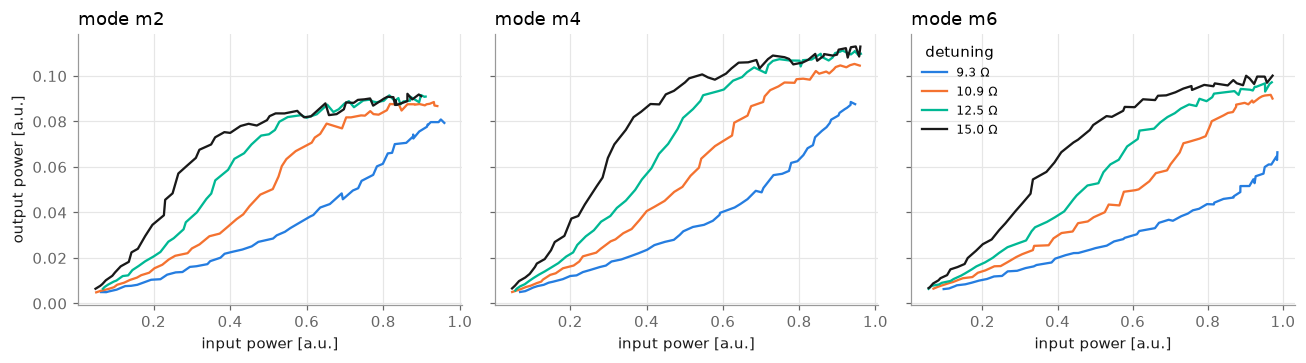

In [2]:
plotting.plot_measured_activations();

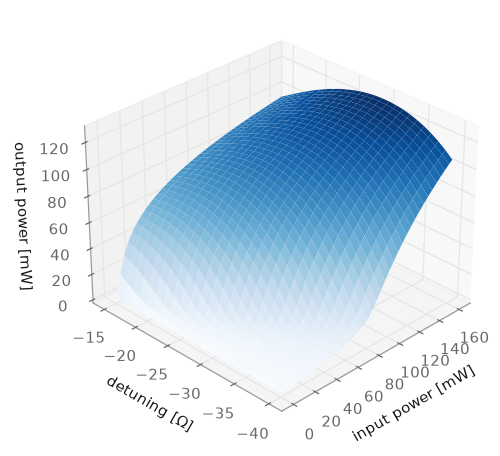

In [3]:
plotting.plot_2d_lookup();

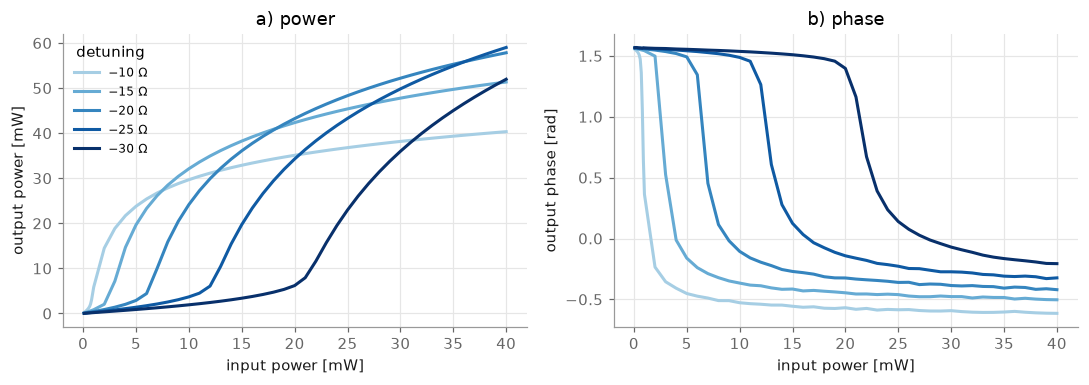

In [4]:
plotting.plot_complex_activations();

## 2. Fixed lookup-table activations (Sec. 3.1)

The network is 784 → *h* → FP-LD activation → 10, trained for 5 epochs with Adam (lr 1e-3, batch 64). Between measured points the activation is interpolated linearly, and outside the measured range it is extrapolated linearly.

**Fig. 3.1**: MNIST accuracy for each measured curve, with a) 25 and b) 64 hidden neurons.

fig3_1_mnist_h25: best-worst spread = 2.74%  (thesis: 2.9%),  mean = 93.67%
fig3_1_mnist_h64: best-worst spread = 4.61%  (thesis: 4.6%),  mean = 94.89%


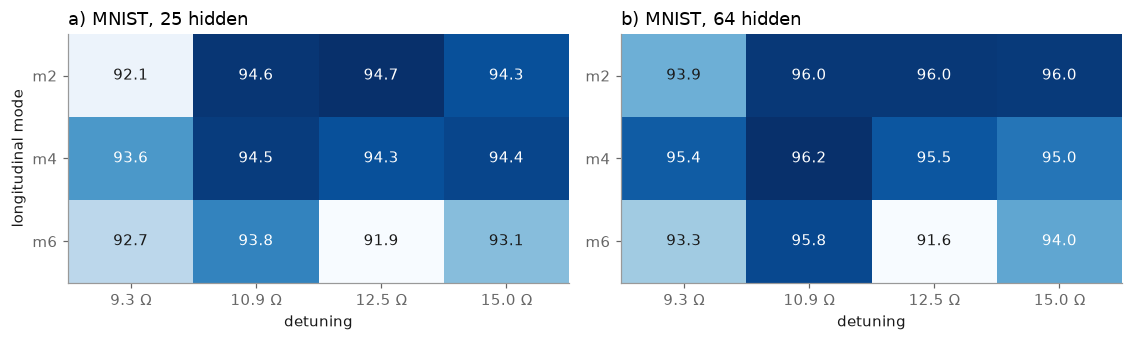

In [5]:
plotting.plot_heatmaps([(R["fig3_1_mnist_h25"], "a) MNIST, 25 hidden"), (R["fig3_1_mnist_h64"], "b) MNIST, 64 hidden")], name="fig3_1_mnist_heatmaps")
for k, h in [("fig3_1_mnist_h25", "h25"), ("fig3_1_mnist_h64", "h64")]:
    a = [f["mean"] for f in R[k]["functions"]]
    print(f"{k}: best-worst spread = {max(a)-min(a):.2f}%  (thesis: {report.PAPER['fig3_1_spread'][h]}%),  mean = {np.mean(a):.2f}%")

**Fig. 3.2**: the same 12 activations on Fashion-MNIST (64 hidden neurons).

mean = 85.08%  (thesis 85.65%)
Pearson correlation MNIST vs Fashion over the 12 activations: r = 0.89


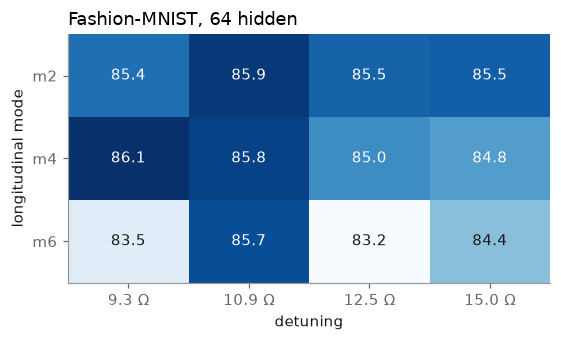

In [6]:
plotting.plot_heatmaps([(R["fig3_2_fashion_h64"], "Fashion-MNIST, 64 hidden")], name="fig3_2_fashion_heatmap")
a = [f["mean"] for f in R["fig3_2_fashion_h64"]["functions"]]
print(f"mean = {np.mean(a):.2f}%  (thesis 85.65%)")
# Do activations that are good on MNIST also do well on Fashion-MNIST?
m = [f["mean"] for f in R["fig3_1_mnist_h64"]["functions"]]
print(f"Pearson correlation MNIST vs Fashion over the 12 activations: r = {np.corrcoef(m, a)[0,1]:.2f}")

## 3. Learnable activation functions (Sec. 3.2)

**Fig. 3.3**: first, each of the 26 curves of the 2D lookup table is used as a fixed activation (10 epochs).

fig3_3_fashion: mean 85.90%, spread 3.17%
fig3_3_mnist: mean 95.67%, spread 4.82%


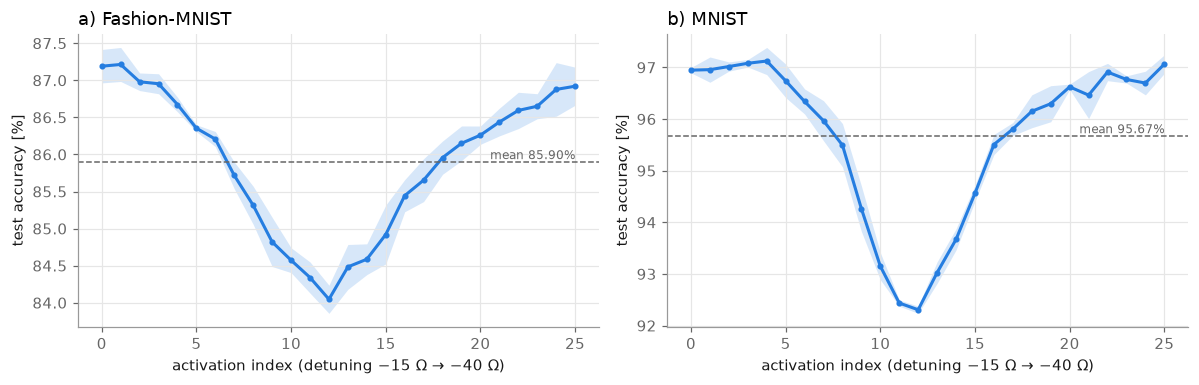

In [7]:
plotting.plot_fixed_2d(R["fig3_3_fashion"], R["fig3_3_mnist"])
for k in ["fig3_3_fashion", "fig3_3_mnist"]:
    a = [f["mean"] for f in R[k]["functions"]]
    print(f"{k}: mean {np.mean(a):.2f}%, spread {max(a)-min(a):.2f}%")

Next, each hidden neuron $i$ learns a distribution over the 26 curves,
$\bar\sigma_i = \mathrm{softmax}(\omega_i)\cdot\Sigma$ (Eq. 2.2). An entropy penalty $\lambda\sum s\log s$ is added to the loss (Eq. 2.4) and pushes each distribution towards a single curve, which is the only kind of activation the hardware can realise. At test time each neuron uses only its argmax curve.

**Fig. 3.4**: the learned distributions for all 64 neurons, a) without and b) with the entropy penalty (Fashion-MNIST).

λ=0.0: mean max-probability per neuron = 0.091
λ=0.1: mean max-probability per neuron = 0.982
λ=0.15: mean max-probability per neuron = 0.996
λ=0.2: mean max-probability per neuron = 0.996


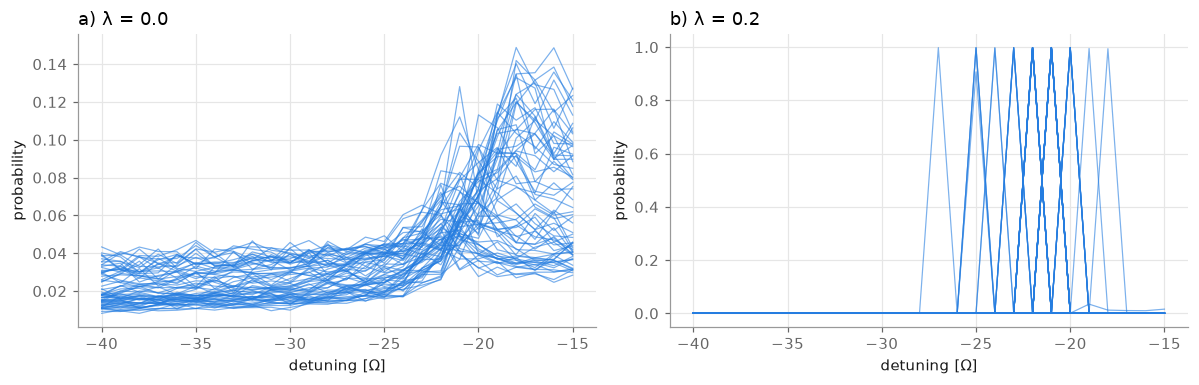

In [8]:
plotting.plot_probabilities(R["tab3_1_fashion_learnable"])
for r in R["tab3_1_fashion_learnable"]["lambdas"]:
    P = np.array(r["probs_seed0"])
    print(f"λ={r['lambda']}: mean max-probability per neuron = {P.max(1).mean():.3f}")

**Table 3.1**: Fashion-MNIST accuracy with the soft mixture (as trained) and with the argmax curve (as deployed).

In [9]:
display(Markdown(report.table_3_1(R["tab3_1_fashion_learnable"])))

| λ | soft (train) — ours | soft — thesis | argmax (test) — ours | argmax — thesis |
|---|---|---|---|---|
| 0.0 | 86.35 ± 0.28 | 86.47 | 85.40 ± 0.64 | 85.79 |
| 0.1 | 86.06 ± 0.14 | 86.22 | 85.96 ± 0.12 | 86.21 |
| 0.15 | 85.97 ± 0.20 | 86.45 | 85.95 ± 0.19 | 86.46 |
| 0.2 | 86.20 ± 0.34 | 86.50 | 86.20 ± 0.34 | 86.50 |

The same experiment on MNIST (the thesis reports only λ = 0.2, at 96.62%):

In [10]:
display(Markdown(report.table_3_1(R["tab3_1_mnist_learnable"], compare=False)))

| λ | soft (train) | argmax (test) |
|---|---|---|
| 0.0 | 96.42 ± 0.15 | 95.59 ± 0.49 |
| 0.1 | 96.17 ± 0.10 | 96.19 ± 0.14 |
| 0.15 | 96.51 ± 0.06 | 96.49 ± 0.02 |
| 0.2 | 96.52 ± 0.08 | 96.51 ± 0.07 |

## 4. Complex-valued networks (Sec. 3.3)

The FP-LD changes the phase of the light as well as its power. In the complex network, |z| passes through the power curve and arg z through the phase curve. Layers are complex linear layers and the logits are |z|. Complex ReLU (applied to the real and imaginary parts separately) is the reference; it cannot yet be built in hardware.

**Table 3.2**: all approaches compared.

In [11]:
display(Markdown(report.table_3_2(R)))
for k in ["tab3_2_complex_mnist", "tab3_2_complex_fashion"]:
    print(k, {a["activation"]: round(a["mean"], 2) for a in R[k]["activations"]})

| network | MNIST — ours | MNIST — thesis | Fashion — ours | Fashion — thesis |
|---|---|---|---|---|
| lookup, measured (mean of 12) | 94.89 | 94.87 | 85.08 | 85.65 |
| lookup, simulated (mean of 26) | 95.67 | 95.63 | 85.90 | 85.80 |
| learnable lookup | 96.51 | 96.62 | 86.20 | 86.50 |
| complex lookup | 96.09 | 96.20 | 85.91 | 85.62 |
| complex ReLU | 96.56 | 96.37 | 86.54 | 86.74 |

Complex lookup: best detuning −10 Ω (MNIST) and −10 Ω (Fashion).

tab3_2_complex_mnist {10: 96.09, 15: 94.34, 20: 95.48, 25: 95.06, 30: 95.88, 'relu': 96.56}
tab3_2_complex_fashion {10: 85.91, 15: 84.76, 20: 84.97, 25: 84.4, 30: 85.19, 'relu': 86.54}


**Fig. 3.5**: MNIST test loss over 20 epochs (SGD, lr 0.01, momentum 0.9). The figure in the thesis compares the **complex-ReLU** network to the real lookup network; the complex-lookup network is shown here as well.

real_lookup     final acc 97.18%   min test loss at epoch 17   final loss 0.0966
complex_relu    final acc 97.66%   min test loss at epoch 19   final loss 0.0787
complex_lookup  final acc 97.09%   min test loss at epoch 17   final loss 0.0984


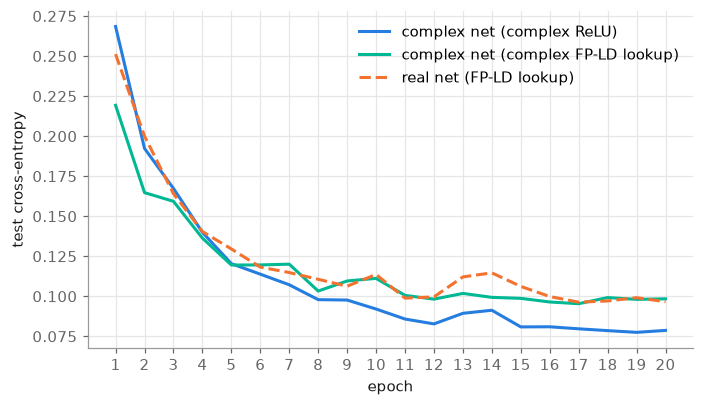

In [12]:
plotting.plot_loss_curves(R["fig3_5_loss_curves"])
for k, v in R["fig3_5_loss_curves"]["nets"].items():
    y = v["test_loss"]
    print(f"{k:15s} final acc {v['final_acc']:.2f}%   min test loss at epoch {int(np.argmin(y))+1}   final loss {y[-1]:.4f}")